# M1 — Explore euro-area yield curves
ECB spot rates, percent, continuous compounding. AAA vs all-issuers.

In [1]:
import warnings
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss
from scenario_lab.data import load_curve

warnings.filterwarnings("ignore")  # statsmodels API/table-range warnings; KPSS p is clipped to [0.01, 0.1]
aaa, allc =load_curve("AAA"), load_curve("ALL")
print(aaa.shape, aaa.index.min().date(), aaa.index.max().date(), "NaN:", int(aaa.isna().sum().sum()))
aaa.describe().round(2)

(5678, 6) 2004-09-06 2026-11-19 NaN: 0


,1Y,2Y,5Y,10Y,20Y,30Y
count,5678.00,5678.00,5678.00,5678.00,5678.00,5678.00
mean,1.02,1.10,1.46,2.04,2.48,2.53
std,1.62,1.59,1.55,1.54,1.52,1.47
min,-0.91,-0.97,-1.00,-0.82,-0.51,-0.43
25%,-0.59,-0.55,-0.14,0.48,1.06,1.26
50%,0.53,0.82,1.73,2.36,2.72,2.61
75%,2.38,2.45,2.69,3.40,3.81,3.84
max,4.54,4.71,4.73,4.78,4.98,5.18


## 1. History of each maturity

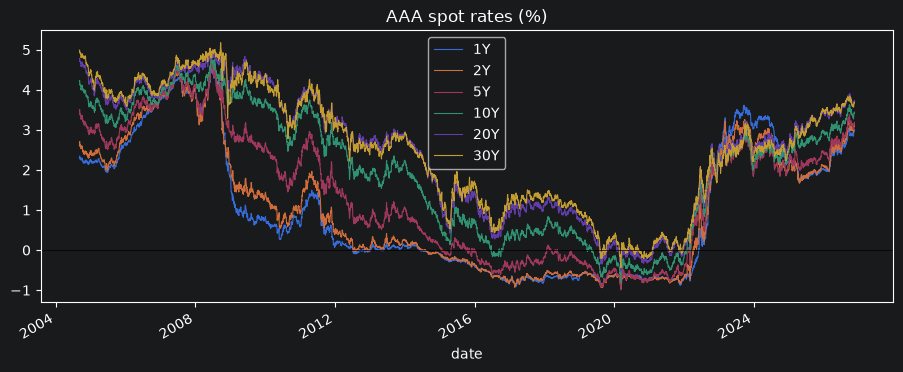

In [2]:
aaa.plot(figsize=(11, 4), lw=0.8, title="AAA spot rates (%)"); plt.axhline(0, c="k", lw=0.5); plt.show()

## 2. Curve shapes on selected dates

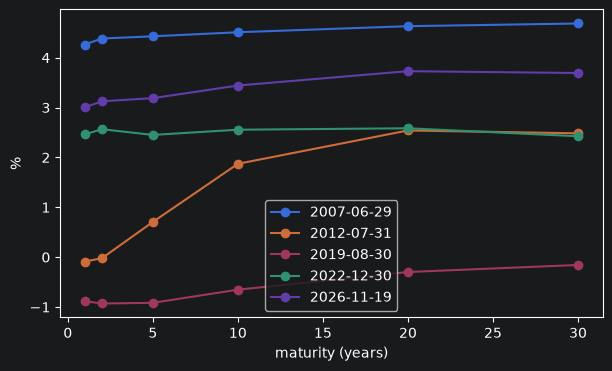

In [3]:
dates = ["2007-06-29", "2012-07-31", "2019-08-30", "2022-12-30", aaa.index[-1]]
fig, ax = plt.subplots(figsize=(7, 4))
for d in dates:
    r = aaa.loc[pd.Timestamp(d)] if pd.Timestamp(d) in aaa.index else aaa.iloc[-1]
    ax.plot([1, 2, 5, 10, 20, 30], r.values, marker="o", label=str(pd.Timestamp(d).date()))
ax.set(xlabel="maturity (years)", ylabel="%"); ax.legend(); plt.show()

## 3. Rate changes (weekly, Friday-to-Friday) and cross-maturity correlation

In [4]:
w = aaa.resample("W-FRI").last()
dw = w.diff().dropna()
print(dw.describe().round(3).loc[["std", "min", "max"]])
print("excess kurtosis:\n", dw.kurt().round(2))
print(dw.corr().round(2))

        1Y     2Y     5Y    10Y    20Y    30Y
std  0.069  0.087  0.093  0.092  0.097  0.107
min -0.608 -0.569 -0.436 -0.361 -0.439 -0.702
max  0.388  0.377  0.417  0.404  0.413  0.432
excess kurtosis:
 1Y     11.12
2Y      5.47
5Y      2.26
10Y     1.07
20Y     1.43
30Y     3.16
dtype: float64
       1Y    2Y    5Y   10Y   20Y   30Y
1Y   1.00  0.92  0.73  0.56  0.43  0.34
2Y   0.92  1.00  0.89  0.70  0.55  0.45
5Y   0.73  0.89  1.00  0.91  0.75  0.64
10Y  0.56  0.70  0.91  1.00  0.92  0.81
20Y  0.43  0.55  0.75  0.92  1.00  0.94
30Y  0.34  0.45  0.64  0.81  0.94  1.00


## 4. Stationarity: levels vs weekly changes
ADF null: unit root. KPSS null: stationary. Read them together; ADF has low power on persistent series.

In [5]:
rows = []
for name, s in [("level", w), ("change", dw)]:
    for c in s.columns:
        rows.append((name, c, adfuller(s[c], autolag="AIC")[1], kpss(s[c], regression="c", nlags="auto")[1]))
res = pd.DataFrame(rows, columns=["series", "mat", "ADF p", "KPSS p"]).round(3)
res.pivot(index="mat", columns="series", values=["ADF p", "KPSS p"])

ADF p        KPSS p      
series change  level change level
mat                              
10Y       0.0  0.646  0.041  0.01
1Y        0.0  0.626  0.074  0.01
20Y       0.0  0.572  0.053  0.01
2Y        0.0  0.731  0.035  0.01
30Y       0.0  0.607  0.050  0.01
5Y        0.0  0.718  0.032  0.01

## 5. Volatility clustering: rolling 1-year std of weekly changes

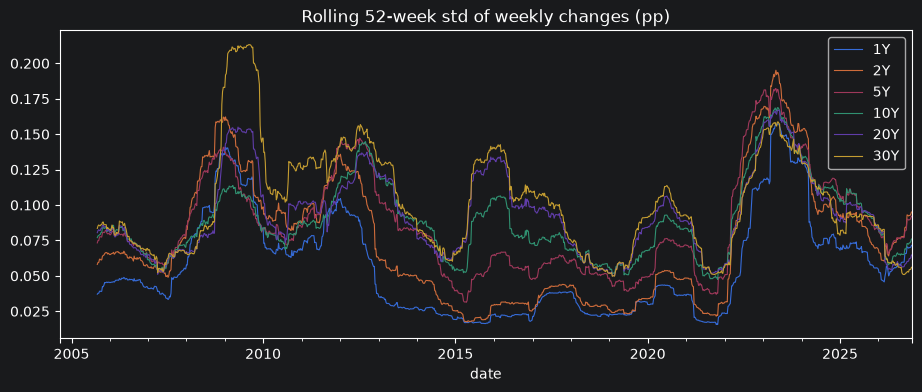

In [6]:
dw.rolling(52).std().plot(figsize=(11, 4), lw=0.8, title="Rolling 52-week std of weekly changes (pp)"); plt.show()

## 6. AAA vs all-issuers

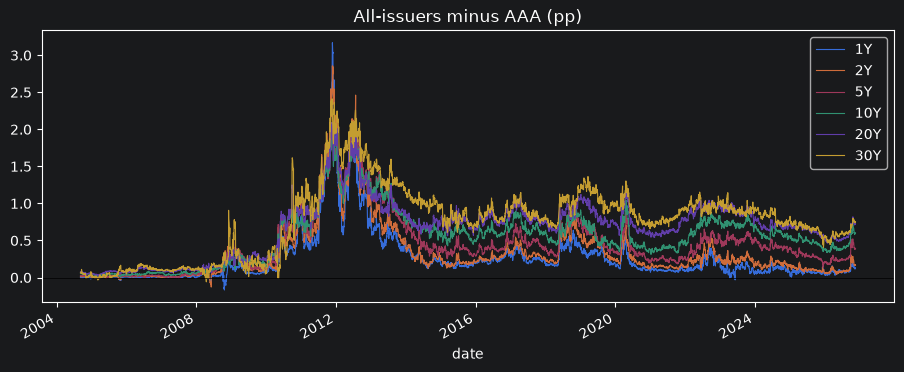

In [7]:
(allc - aaa).plot(figsize=(11, 4), lw=0.8, title="All-issuers minus AAA (pp)"); plt.axhline(0, c="k", lw=0.5); plt.show()